---------------------------------------------------

In [1]:
# Imports
import re
import torch
import pickle
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# Copies code from github (https://github.com/moeschl21/TransformerLSR_moeschl.git) into the working directory 
!git clone https://github.com/moeschl21/TransformerLSR_moeschl.git
!cp -r TransformerLSR_moeschl/* /kaggle/working/
!rm -rf TransformerLSR_moeschl

Cloning into 'TransformerLSR_moeschl'...
remote: Enumerating objects: 292, done.
remote: Counting objects: 100% (127/127), done.
remote: Compressing objects: 100% (127/127), done.
remote: Total 292 (delta 72), reused 0 (delta 0), pack-reused 165 (from 1)
Receiving objects: 100% (292/292), 153.66 KiB | 3.57 MiB/s, done.
Resolving deltas: 100% (173/173), done.


In [6]:
!mkdir -p data results models

In [14]:
# Copies data from dataset
!cp -r /kaggle/input/datasets/jonasmschl/data-lsr-59/data_lsr/. /kaggle/working/data/

In [23]:
# Copies models from dataset
!cp -r /kaggle/input/datasets/jonasmschl/data-lsr-59/59_censoring_model_LSR/. /kaggle/working/models/

In [3]:
# Setting up variables
num_sim = 100 # Number of Simulations
num_traj = 100 # Number of patients
timeout = 1000 # Maximum visits
batch_size = 16
num_enc_layer = 2 #2
num_dec_layer = 3 #3
lr = 0.0001 #0.0001
model_size = 64 # Embedding size 64
epoch = 100

In [ ]:
########################################################################
############################## EVALUATION ##############################
########################################################################

In [4]:
# Install Module Lifelines for eval.py
!pip install lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 6.6 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 3.6 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=c1b7a04259112e754b6f57e34444205e7618c03c2dc26e5a78c6f2b61d71fe7d
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma


In [5]:
import logging

logger = logging.getLogger()

for handler in logger.handlers[:]:
    logger.removeHandler(handler)

In [24]:
# Evaluating the models and saves the results in the result folder
for seed in range(1,num_sim + 1):
    print(f"##################### Seed: {seed} #####################")
    !python eval.py \
      --seed {seed} \
      --batch_size {batch_size} \
      --num_enc_layer {num_enc_layer} \
      --num_dec_layer {num_dec_layer} \
      --lr {lr} \
      --model_size {model_size} \
      --local \
      --data DIVAT_sim_missing_{num_traj}_visit_{timeout}_long_3 

    if seed == num_sim:
        print("done")

    logger = logging.getLogger()

    for handler in logger.handlers[:]:
        logger.removeHandler(handler)

##################### Seed: 1 #####################
[ Sat Oct 17 15:12:57 2026 ] Namespace(seed=1, batch_size=16, num_enc_layer=2, num_dec_layer=3, num_head=4, model_size=64, suffix='eval', model='LSR', d_long=3, data='DIVAT_sim_missing_100_visit_1000_long_3', local=True, Y1_missing=0, Y2_missing=0, Y3_missing=0, inten_weight=0.01, surv_weight=0.1, lr=0.0001)
[ Sat Oct 17 15:12:57 2026 ] ==================================================
[ Sat Oct 17 15:12:57 2026 ] Starting evaluation for dataset: DIVAT_sim_missing_100_visit_1000_long_3
[ Sat Oct 17 15:12:57 2026 ] 4 heads, 2 enc layers,3 dec layers, 64 model dimension
[ Sat Oct 17 15:12:57 2026 ] Data containing total 100 trajectories
[ Sat Oct 17 15:12:57 2026 ] ==================================================
LT: 427.36404217223145
pred_times: [ 727.85214001  865.85377277  928.70710305  964.45220144 1012.68321856
 1121.2360194 ]
pred_times[0] - LT: 300.4880978390615
##################### Seed: 2 #####################
[ Sat Oct 17

In [25]:
# Calculate censoring rate
censoring_rates = []
files = glob.glob('./data/*.pkl')
for file in files:
    if "Info" in file or "info" in file:
        continue

    with open(file, 'rb') as f:
        res = pickle.load(f)
    deathrate = res.groupby("id")["event"].first().mean()
    censoring_rates.append(1 - deathrate)

censorring_rate = sum(censoring_rates) / len(censoring_rates)

print(f"Censoring rate is: {censorring_rate*100}%")

Censoring rate is: 59.28000000000003%


In [30]:
# Load results and extract seed numbers
results = []
files = sorted(glob.glob('./results/DIVAT_*.pkl'))

for file in files:
    with open(file, 'rb') as f:
        res = pickle.load(f)

    seed = int(re.search(r'_seed(\d+)_', file).group(1))
    res['seed'] = seed
    results.append(res)

df = pd.DataFrame(results)
df = df.sort_values("seed").reset_index(drop=True)

# Seeds excluded from all metrics
excluded_all_seeds = [89]

# Exclude seed 89 (joineRML didnt conv.)
df = df[~df["seed"].isin(excluded_all_seeds)].reset_index(drop=True)

# Seeds excluded from IBS comparison with joineRML
excluded_ibs_seeds = [5,10,13,19,31,42,43,56,62,71,72,73,75,76,77,84,86,89,92,99]

# Exclude these seeds only from IBS
df.loc[df["seed"].isin(excluded_ibs_seeds), "ibs"] = np.nan

# Define evaluation metrics
metrics = ["Y1err", "Y2err", "Y3err", "ibs", "surv_ll_err", "visit_ll_err"]

# Separate plotting data
df_inten = df[["seed","visit_log_inten_list", "visit_log_inten_truth", "visit_times"]]
df_long = df[["seed","long_times", "Y1_pred", "Y1_truth", "Y2_pred", "Y2_truth", "Y3_pred", "Y3_truth", "long_nan_mask"]]
df_mean_surv = df[["seed","total_pred_plot", "mean_surv_plot", "pred_times_plot"]]

# Keep only evaluation metrics for summary
df_metrics = df[metrics]

# Calculate mean and standard deviation across seeds
summary = pd.DataFrame({
    "mean": df_metrics.mean(axis=0, skipna=True),
    "std": df_metrics.std(axis=0, ddof=1, skipna=True)
})

summary["mean_pm_std"] = (
    summary["mean"].round(3).astype(str) + " ± " +
    summary["std"].round(3).astype(str)
)

summary_metrics = summary.loc[metrics].copy()

# Display results
print(df[["seed"] + metrics])
print(summary_metrics)

    seed     Y1err     Y2err     Y3err       ibs  surv_ll_err  visit_ll_err
0      1  0.309550  0.338732  0.334738  0.165479     0.770285      0.462517
1      2  0.333107  0.469935  0.361000  0.189398     0.498827      1.163055
2      3  0.258637  0.418132  0.314297  0.124300     0.615452      0.526050
3      4  0.275113  0.371835  0.272814  0.189820     0.986476      1.047066
4      5  0.297819  0.447491  0.331995       NaN     0.612645      0.457452
..   ...       ...       ...       ...       ...          ...           ...
94    96  0.319135  0.430371  0.275868  0.196707     0.687172      0.925873
95    97  0.370993  0.423185  0.303732  0.197557     0.620911      1.084691
96    98  0.275002  0.435369  0.314810  0.205458     0.784264      0.648117
97    99  0.247719  0.401152  0.332218       NaN     0.656383      0.889760
98   100  0.281678  0.451975  0.326742  0.171566     0.651660      0.509354

[99 rows x 7 columns]
                  mean       std    mean_pm_std
Y1err         0.2

In [31]:
# Output the metrics
print(f"For censoring rate {censorring_rate*100}%:")
print(f"")
for metric in metrics:
    print(f"{metric:<15} : {summary.loc[metric, "mean_pm_std"]}")

For censoring rate 59.28000000000003%:

Y1err           : 0.296 ± 0.043
Y2err           : 0.42 ± 0.059
Y3err           : 0.329 ± 0.025
ibs             : 0.185 ± 0.033
surv_ll_err     : 0.665 ± 0.14
visit_ll_err    : 0.853 ± 0.281


In [36]:
# Get ground truth for survival plot
for seed in range(1,5 + 1):
    print(f"##################### Predicted Survival: Seed {seed} #####################")
    
    !python oracle_survival.py \
      --data_path /kaggle/input/datasets/jonasmschl/data-lsr-59/98_withoutmissing/59_censoring/DIVAT_sim_100_visit_1000_long_3_seed_{seed}.pkl \
      --patient_info_path /kaggle/input/datasets/jonasmschl/data-lsr-59/98_withoutmissing/59_censoring/DIVAT_sim_100_visit_1000_long_3_seed_{seed}_patientInfo.pkl \
      --simulation_py data_simulation.py \
      --n_paths 500 \
      --horizon 16000 \
      --output_path results/predict_survival_seed_{seed}.pkl

##################### Predicted Survival: Seed 1 #####################
[01/16] patient 80: last visit=0.000, LT=427.364, Y3=2.340
[02/16] patient 81: last visit=180.869, LT=427.364, Y3=2.366
[03/16] patient 82: last visit=407.975, LT=427.364, Y3=2.480
[04/16] patient 83: last visit=391.831, LT=427.364, Y3=2.426
[05/16] patient 86: last visit=185.099, LT=427.364, Y3=2.534
[06/16] patient 87: last visit=392.625, LT=427.364, Y3=2.712
[07/16] patient 88: last visit=412.917, LT=427.364, Y3=2.168
[08/16] patient 89: last visit=0.000, LT=427.364, Y3=2.236
[09/16] patient 90: last visit=304.990, LT=427.364, Y3=2.432
[10/16] patient 92: last visit=405.318, LT=427.364, Y3=2.974
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
censored
[11/16] patient 93: last visit=365.883, LT=427.364, Y3=2.640
[12/16] patient 94: last vis

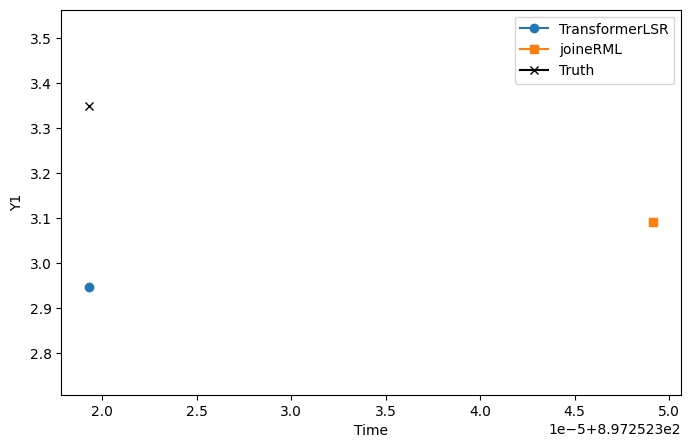

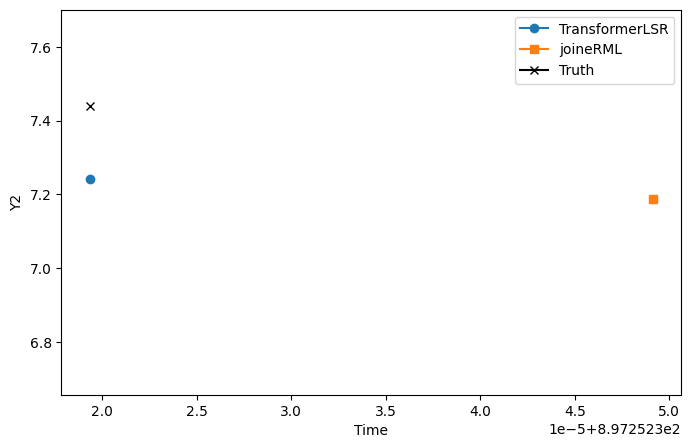

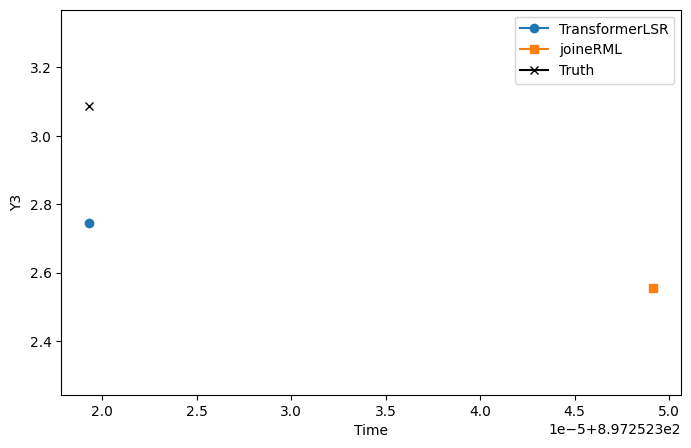

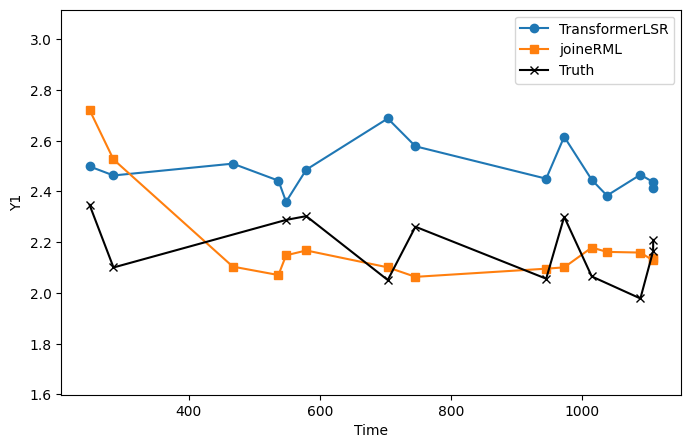

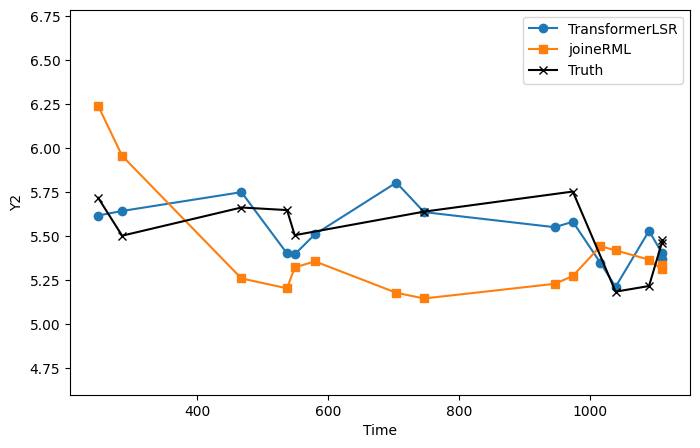

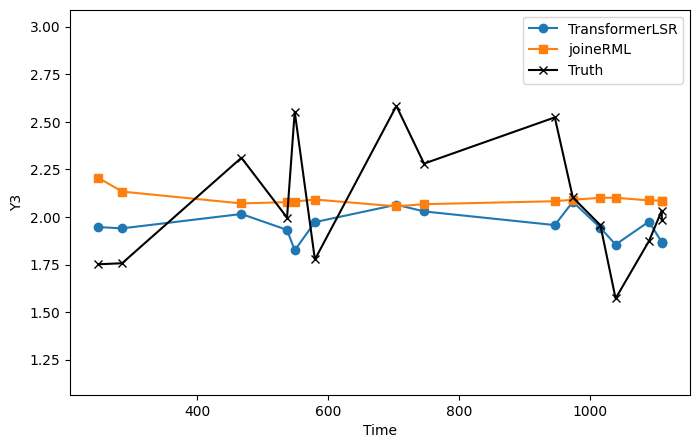

/tmp/ipykernel_56/3955592794.py:59: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.ylim(y_min - margin, y_max + margin)


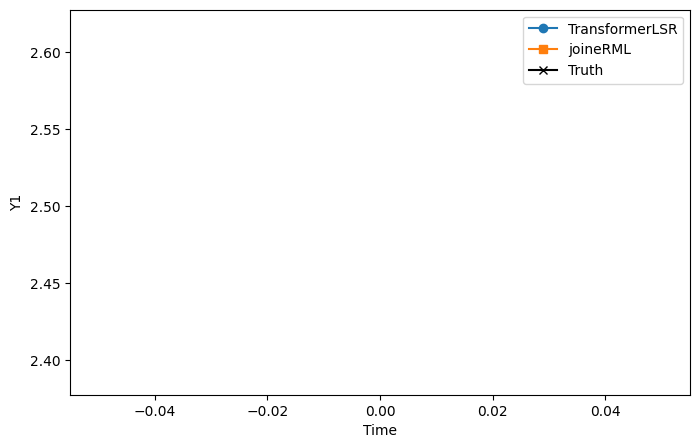

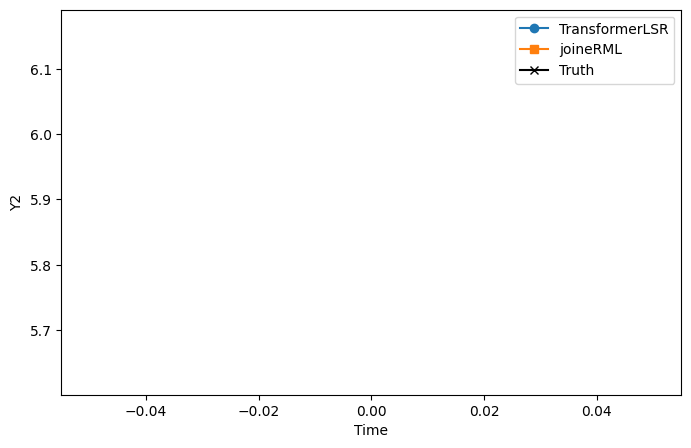

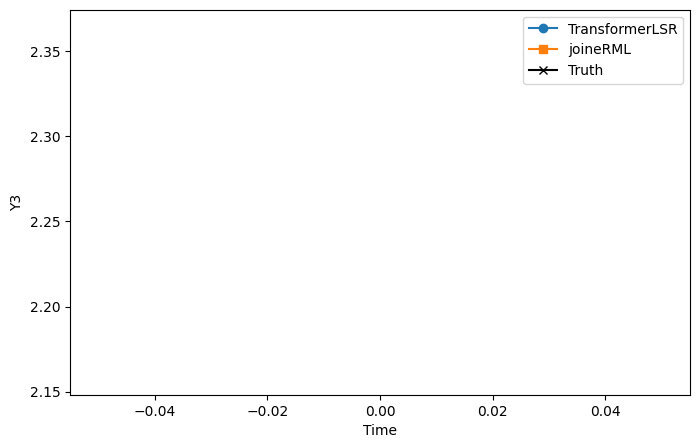

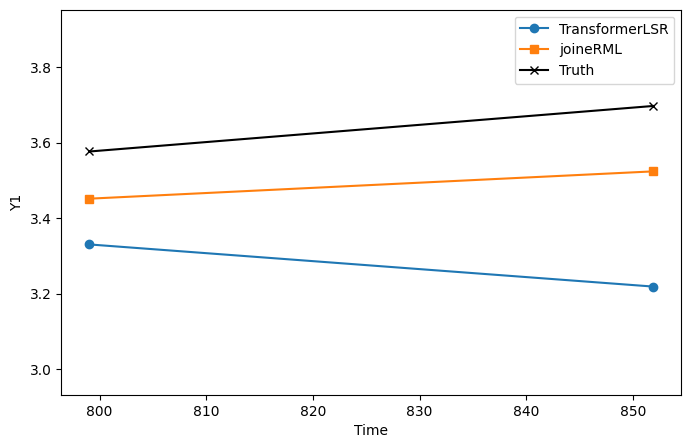

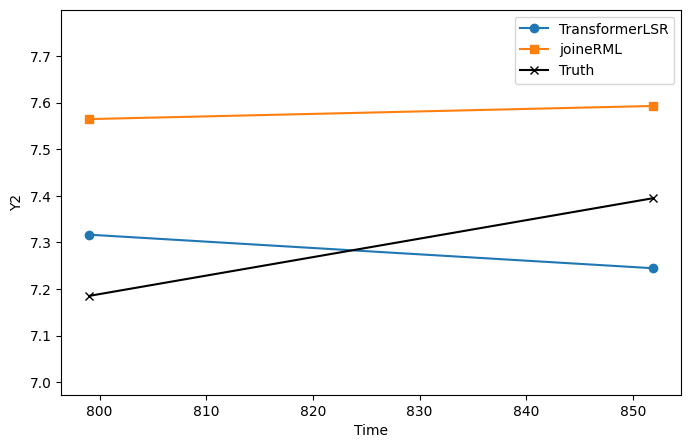

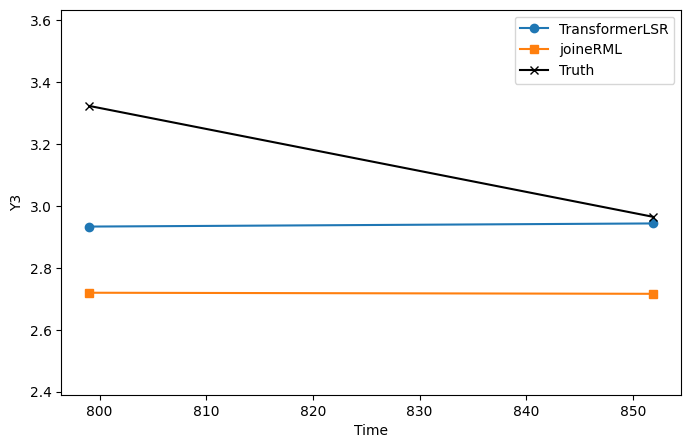

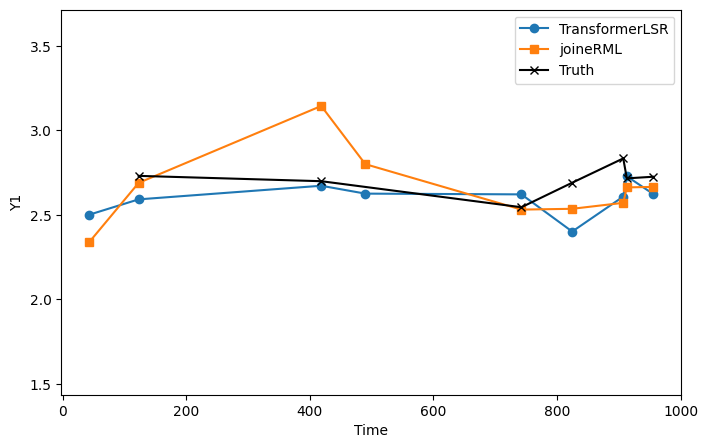

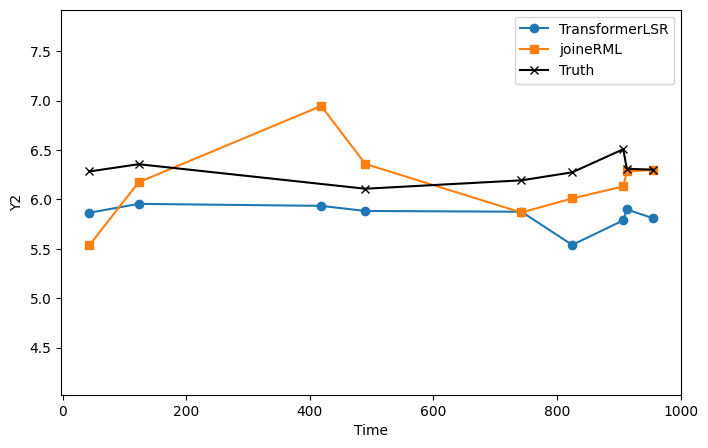

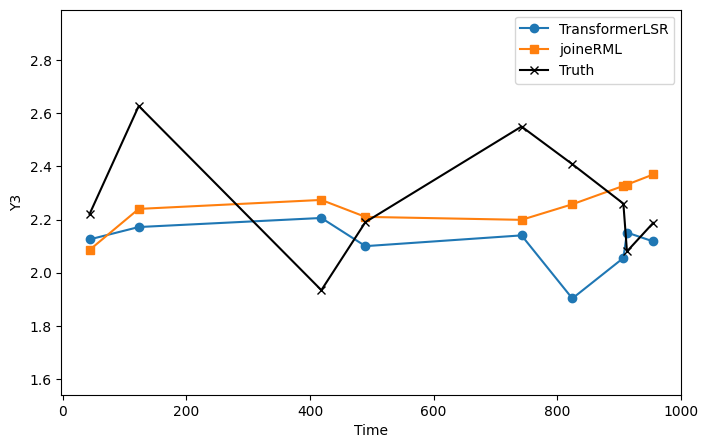

In [40]:
# Plotting longitudinal outcomes
eval_data_path = "/kaggle/input/datasets/jonasmschl/data-lsr-59/59_eval_data"

for i in range(5):

    seed = i + 1

    times = np.array(df_long.loc[i, "long_times"])
    nan_mask = np.array(df_long.loc[i, "long_nan_mask"])

    # joineRML results for the same seed
    joinerml = pd.read_csv(
        f"{eval_data_path}/long_results_seed_{seed}.csv"
    )

    # Same test patient as TransfomerLSR
    pid = 80

    for j in range(3):

        y = j + 1

        # LSR
        pred = np.array(df_long.loc[i, f"Y{y}_pred"])
        truth = np.array(df_long.loc[i, f"Y{y}_truth"])

        valid = ~nan_mask[:, j]

        # joineRML
        joinerml_y = (
            joinerml[
                (joinerml["id"] == pid) &
                (joinerml["outcome"] == f"Y{y}")
            ]
            .sort_values("obstime")
        )

        plt.figure(figsize=(8, 5))

        # LSR Prediction 
        plt.plot(times[1:], pred[1:], marker="o", label="TransformerLSR")

        # joineRML
        plt.plot(joinerml_y["obstime"].iloc[1:], joinerml_y["predicted"].iloc[1:], marker="s", label="joineRML")

        # Truth only where Y was observerd
        plt.plot(times[1:][valid[1:]], truth[1:][valid[1:]], marker="x",color="black",label="Truth")

        all_values = np.concatenate([
            pred[1:],
            joinerml_y["predicted"].to_numpy(),
            truth[1:][valid[1:]]
        ])
        
        y_min = np.min(all_values)
        y_max = np.max(all_values)
        margin = 0.5 * (y_max - y_min)
        
        plt.ylim(y_min - margin, y_max + margin)
        plt.xlabel("Time")
        plt.ylabel(f"Y{y}")
        #plt.title(f"Seed {seed} - Y{y}")
        plt.legend()
        plt.show()

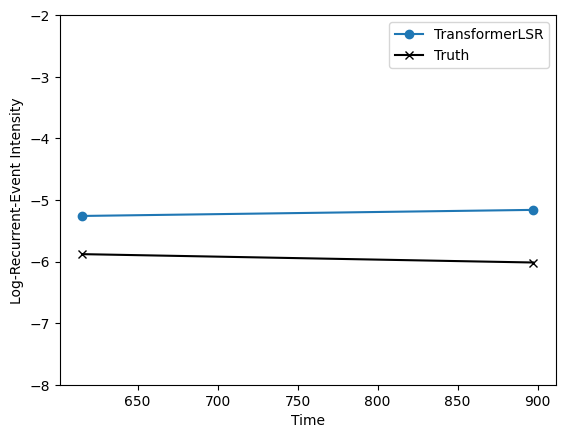

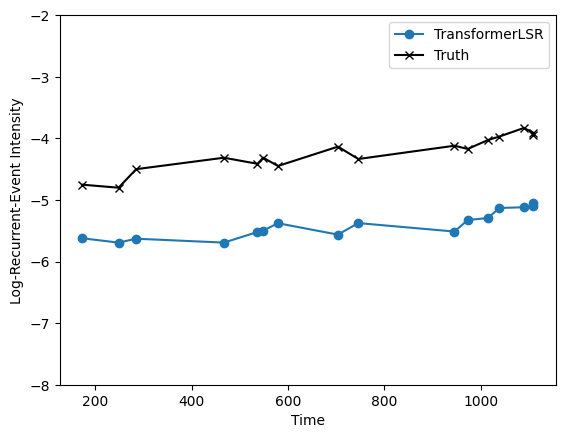

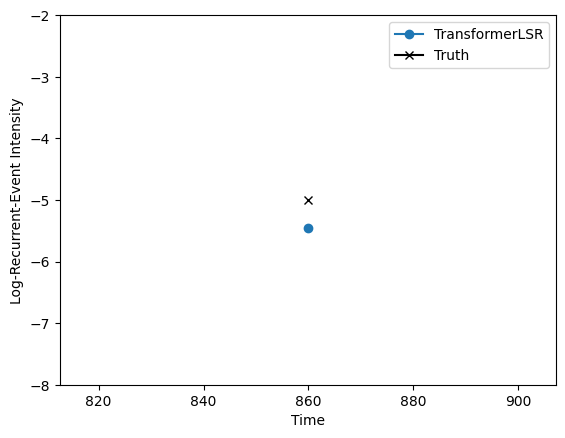

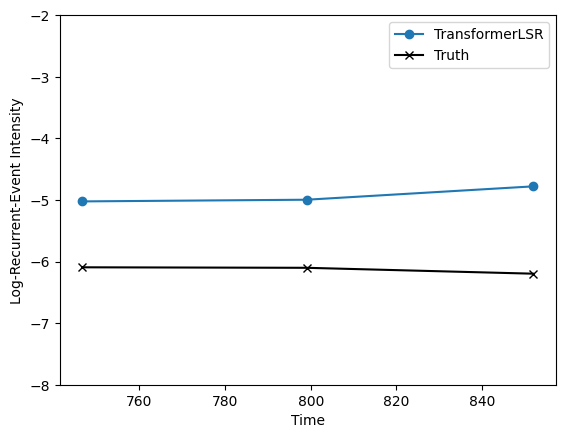

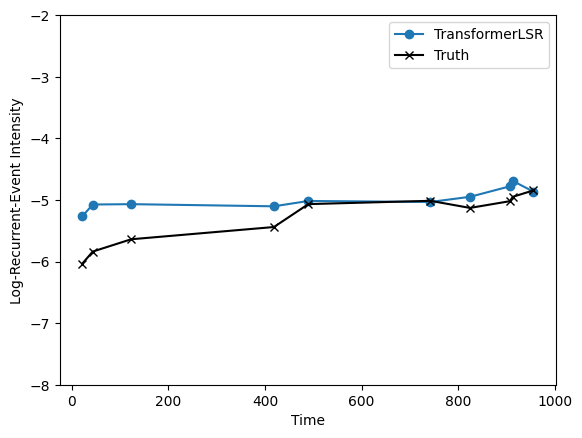

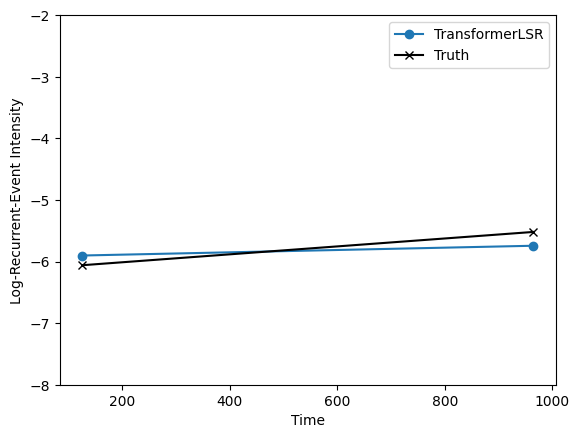

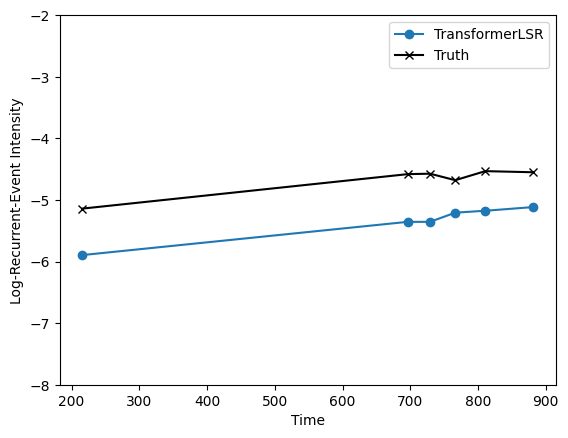

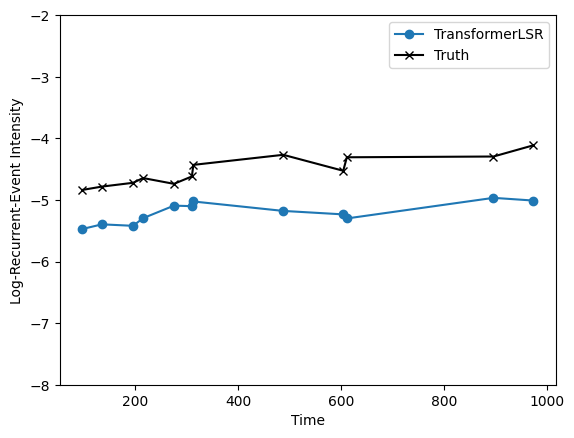

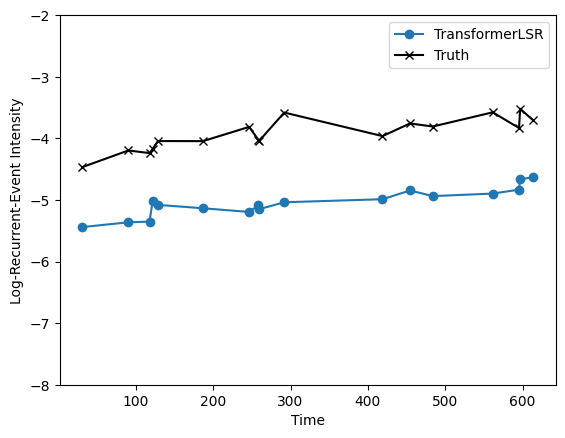

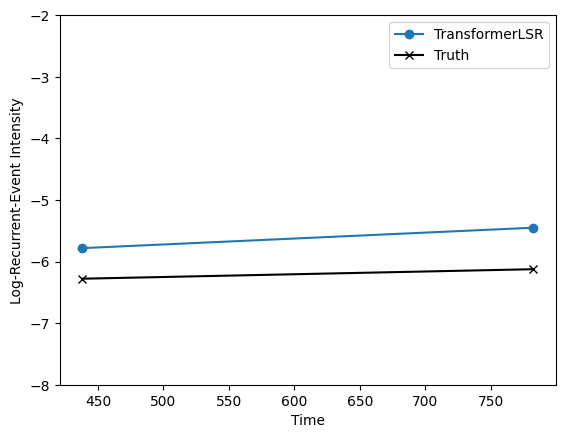

In [41]:
# Plotting recurrent event intensity
for i in range(10):
    plt.figure()
    plt.plot(df_inten["visit_times"][i], df_inten["visit_log_inten_list"][i], marker="o", label="TransformerLSR")
    plt.plot(df_inten["visit_times"][i], df_inten["visit_log_inten_truth"][i], marker="x", color="black", label="Truth")
    

    plt.xlabel("Time")
    plt.ylabel("Log-Recurrent-Event Intensity")
    plt.ylim(-8, -2)
    plt.legend()
    plt.show()

Seed 1: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


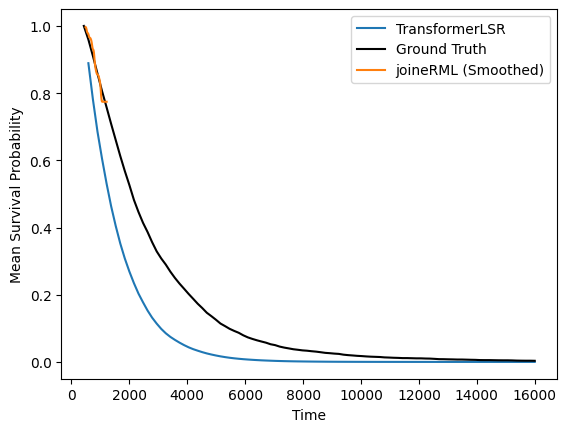

Seed 2: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


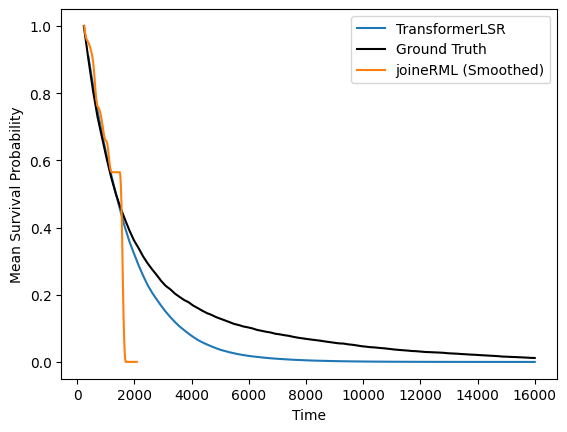

Seed 3: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


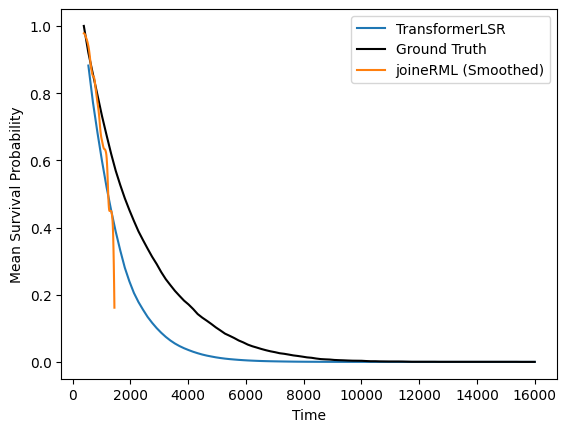

Seed 4: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


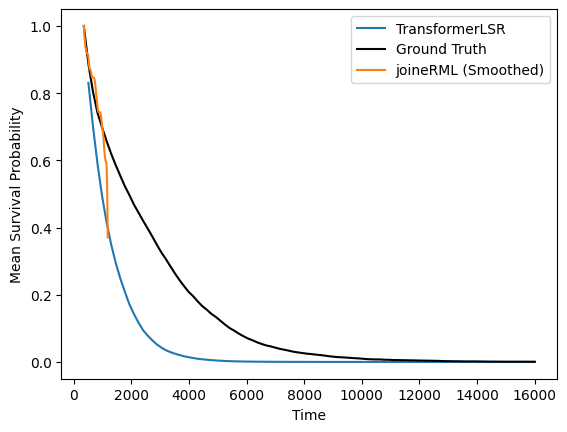

Seed 5: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


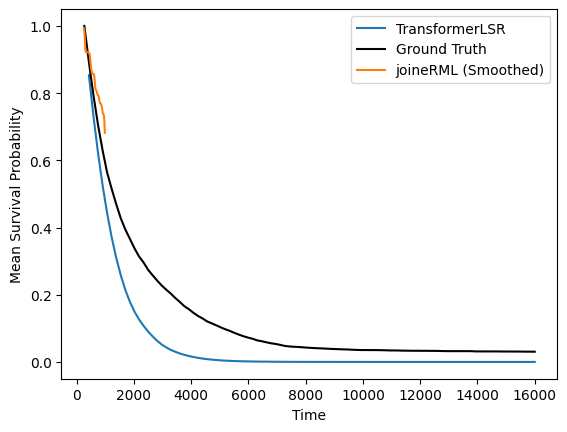

In [42]:
# Plotting Mean survival curve
for i in range(5):

    seed = i + 1

    # LSR
    pred_times = np.array(df_mean_surv.loc[i,"pred_times_plot"])
    mean_surv = np.array(df_mean_surv.loc[i,"mean_surv_plot"])

    valid_idx = pred_times >= df["LT"][i]

    # GT
    with open(f"results/predict_survival_seed_{seed}.pkl", "rb") as f:
        result_surv = pickle.load(f)
    print(f"Seed {seed}:", result_surv.keys())

    # joineRML
    joinerml = pd.read_csv(
        f"{eval_data_path}/mean_surv_smooth_joinerml_seed_{seed}.csv"
    )
    
    plt.figure()
    # LSR
    plt.plot(pred_times[valid_idx], mean_surv[valid_idx], label="TransformerLSR")
    # GT
    plt.plot(result_surv["plot_times"], result_surv["mean_oracle_surv"], color="black", label="Ground Truth")
    # joineRML
    #plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 2], label="joineRML")
    plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 3], label="joineRML (Smoothed)")
    

    plt.xlabel("Time")
    plt.ylabel("Mean Survival Probability")
    plt.legend()
    plt.show()

Seed 1: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


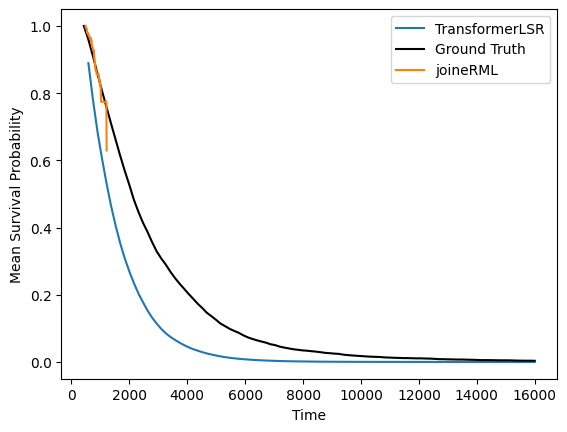

Seed 2: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


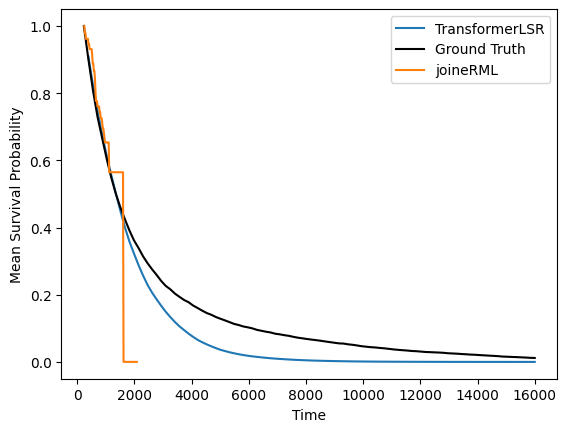

Seed 3: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


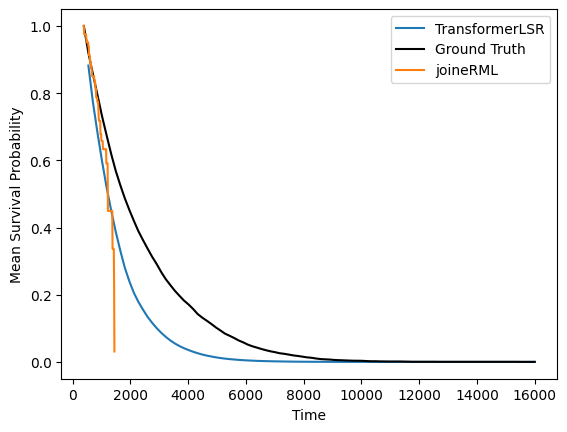

Seed 4: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


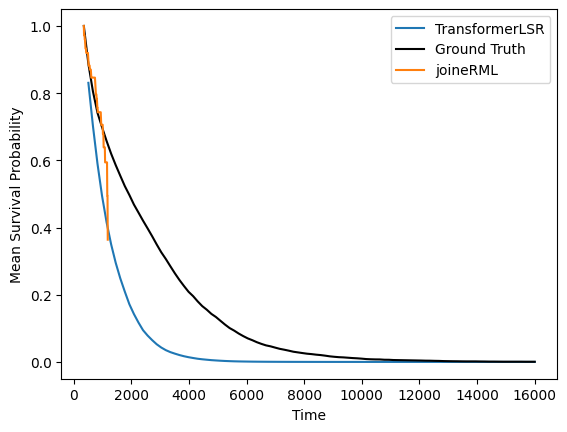

Seed 5: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


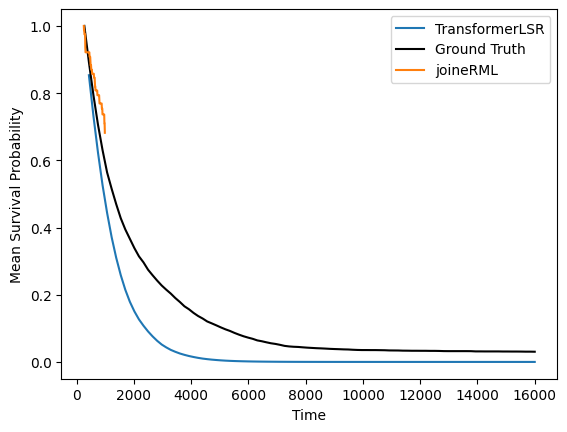

In [43]:
# Plotting Mean survival curve
for i in range(5):

    seed = i + 1

    # LSR
    pred_times = np.array(df_mean_surv.loc[i,"pred_times_plot"])
    mean_surv = np.array(df_mean_surv.loc[i,"mean_surv_plot"])

    valid_idx = pred_times >= df["LT"][i]

    # GT
    with open(f"results/predict_survival_seed_{seed}.pkl", "rb") as f:
        result_surv = pickle.load(f)
    print(f"Seed {seed}:", result_surv.keys())

    # joineRML
    joinerml = pd.read_csv(
        f"{eval_data_path}/mean_surv_smooth_joinerml_seed_{seed}.csv"
    )
    
    plt.figure()
    # LSR
    plt.plot(pred_times[valid_idx], mean_surv[valid_idx], label="TransformerLSR")
    # GT
    plt.plot(result_surv["plot_times"], result_surv["mean_oracle_surv"], color="black", label="Ground Truth")
    # joineRML
    plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 2], label="joineRML")
    #plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 3], label="joineRML (Smoothed)")
    

    plt.xlabel("Time")
    plt.ylabel("Mean Survival Probability")
    plt.legend()
    plt.show()